# Core sampling function

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
def sample_means(population_func, sample_sizes, n_repeats=2000, seed=42):
    rng = np.random.default_rng(seed)
    results = {}
    for n in sample_sizes:
        means = [population_func(rng, n).mean() for _ in range(n_repeats)]
        results[n] = np.array(means)
    return results


# Visulisation 1: CLT acrosee increeasing sample sizes

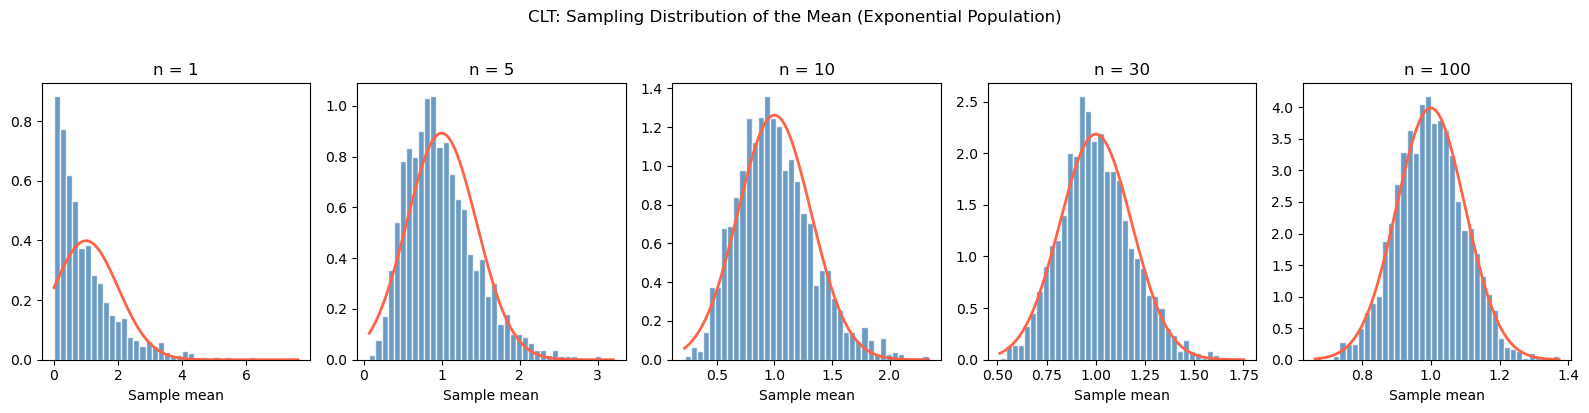

In [14]:
sample_sizes = [1, 5, 10, 30, 100]
pop_exponential = lambda rng, n: rng.exponential(scale=1.0, size=n)
true_mean, true_std = 1.0, 1.0

results = sample_means(pop_exponential, sample_sizes, n_repeats=2000)

fig, axes = plt.subplots(1, len(sample_sizes), figsize=(16, 4), sharey=False)

for ax, n in zip(axes, sample_sizes):
    means = results[n]
    ax.hist(means, bins=40, density=True, color='steelblue', edgecolor='white', alpha=0.8)
    theoretical_std = true_std / np.sqrt(n)
    x = np.linspace(means.min(), means.max(), 200)
    ax.plot(x, norm.pdf(x, true_mean, theoretical_std), color='tomato', lw=2)
    ax.set_title(f'n = {n}')
    ax.set_xlabel('Sample mean')

fig.suptitle('CLT: Sampling Distribution of the Mean (Exponential Population)', y=1.02)
plt.tight_layout()
plt.savefig('clt_exponential.png', dpi=150, bbox_inches='tight')
plt.show()


### CLT — Exponential Population

At n=1, the sampling distribution mirrors the raw exponential population — strongly right-skewed with a long tail. By n=10 the distribution visibly shifts toward symmetry, and by n=30 the histogram closely matches the theoretical normal curve (red). At n=100 the fit is nearly perfect, with the spread also noticeably narrower. This progression directly demonstrates the CLT: regardless of the population shape, the sampling distribution of the mean converges to normal as n grows.

n=1时，抽样分布完全反映了原始指数分布的形状——明显右偏、有长尾。到n=10时分布已明显趋向对称，n=30时直方图与理论正态曲线（红色）高度吻合，n=100时拟合几乎完美，同时分布的宽度也明显收窄。这一过程直接展示了CLT：不管原始总体是什么形状，样本均值的分布随n增大趋向正态分布。

# Visulization 2: CLT holds for different population shapes

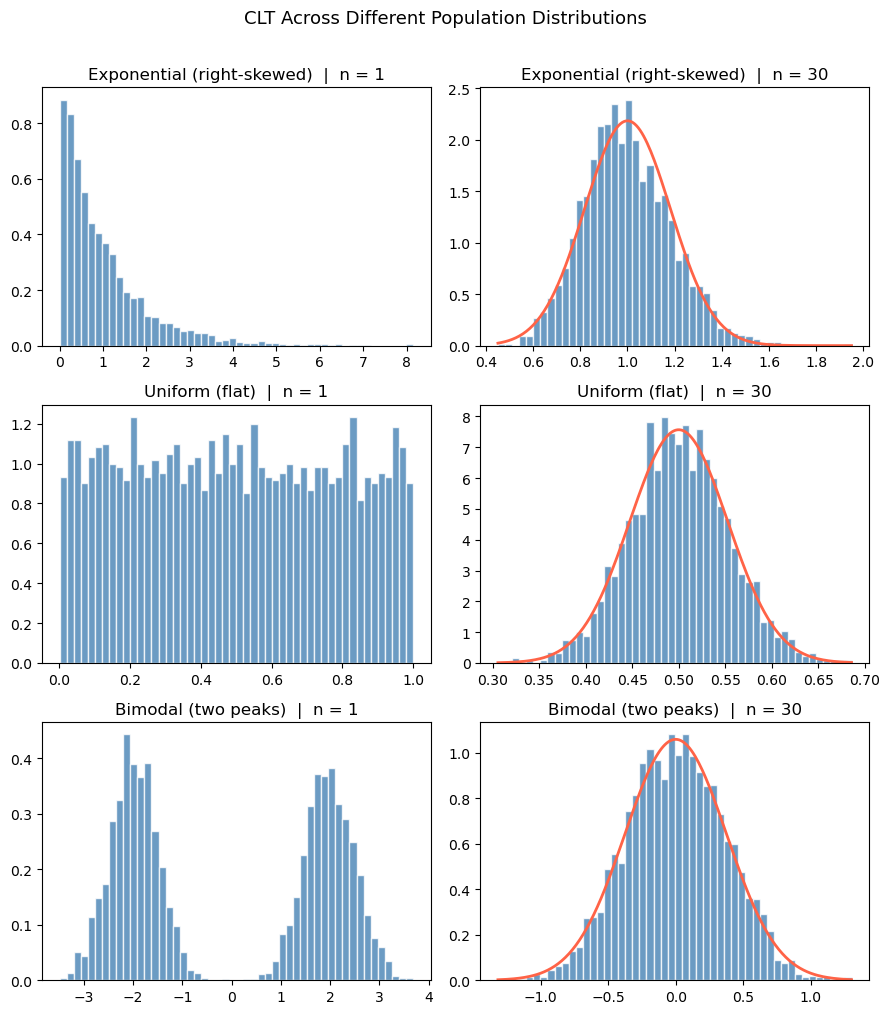

In [16]:
populations = {
    'Exponential (right-skewed)': {
        'func': lambda rng, n: rng.exponential(scale=1.0, size=n),
        'mean': 1.0, 'std': 1.0,
    },
    'Uniform (flat)': {
        'func': lambda rng, n: rng.uniform(0, 1, size=n),
        'mean': 0.5, 'std': 1 / np.sqrt(12),
    },
    'Bimodal (two peaks)': {
        'func': lambda rng, n: np.where(
            rng.random(n) < 0.5,
            rng.normal(-2, 0.5, n),
            rng.normal(2, 0.5, n)
        ),
        'mean': 0.0, 'std': np.sqrt(0.25 + 4),
    },
}

ns_to_show = [1, 30]
fig, axes = plt.subplots(len(populations), 2, figsize=(9, 10))

for row, (name, pop) in enumerate(populations.items()):
    res = sample_means(pop['func'], ns_to_show, n_repeats=3000, seed=row)
    for col, n in enumerate(ns_to_show):
        ax = axes[row, col]
        means = res[n]
        ax.hist(means, bins=50, density=True, color='steelblue', edgecolor='white', alpha=0.8)
        if n >= 10:
            x = np.linspace(means.min(), means.max(), 200)
            ax.plot(x, norm.pdf(x, pop['mean'], pop['std']/np.sqrt(n)), color='tomato', lw=2)
        ax.set_title(f'{name}  |  n = {n}')

fig.suptitle('CLT Across Different Population Distributions', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('clt_distributions.png', dpi=150, bbox_inches='tight')
plt.show()


### CLT — Three Distributions

All three populations — exponential (skewed), uniform (flat), and bimodal (two peaks) — look completely different at n=1. Yet at n=30, all three sampling distributions closely follow the theoretical normal curve (red). This is the most compelling demonstration of the CLT’s universality: the theorem holds regardless of the original population shape, as long as the population has finite mean and variance.

三种原始分布——指数分布（偏态）、均匀分布（平坦）、双峰分布（两个峰）——在n=1时形状完全不同。但到n=30时，三者的抽样分布都与理论正态曲线（红色）高度吻合。这是CLT普适性最有力的展示：只要总体有有限的均值和方差，定理对任何原始分布形状都成立。

# Visulization 3: Convergence to normality - QQ plots

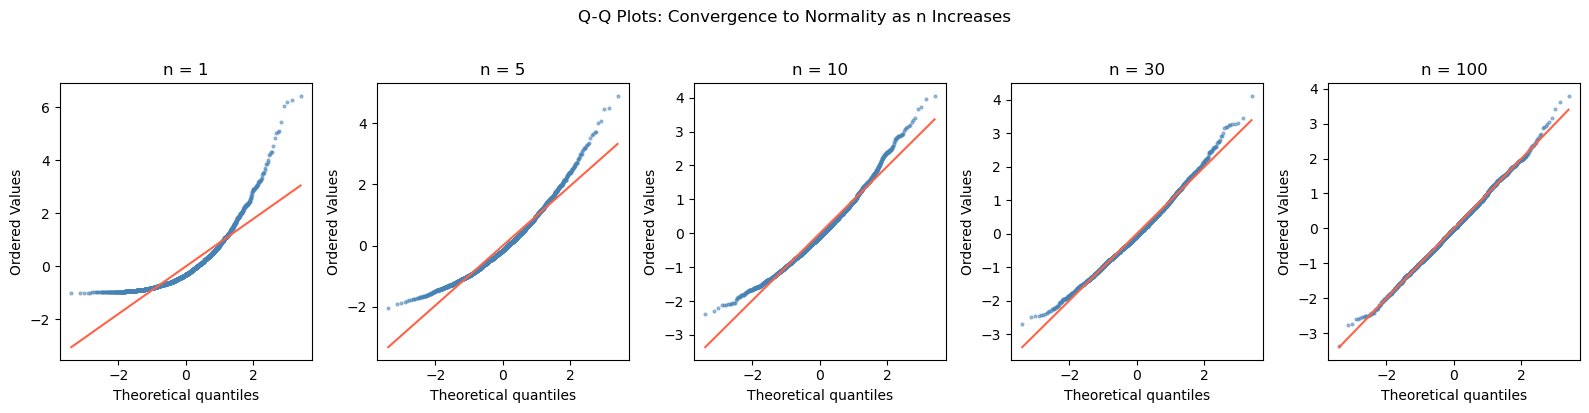

In [18]:
from scipy.stats import probplot

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, n in zip(axes, [1, 5, 10, 30, 100]):
    means = results[n]
    z = (means - means.mean()) / means.std()
    probplot(z, dist='norm', plot=ax)
    ax.set_title(f'n = {n}')
    ax.get_lines()[0].set(markersize=2, alpha=0.5, color='steelblue')
    ax.get_lines()[1].set(color='tomato', lw=1.5)

fig.suptitle('Q-Q Plots: Convergence to Normality as n Increases', y=1.02)
plt.tight_layout()
plt.savefig('clt_qq.png', dpi=150, bbox_inches='tight')
plt.show()


### Q-Q Plots

At n=1 the points deviate strongly from the diagonal — the heavy right tail of the exponential distribution creates a pronounced upward curve. By n=10 the middle section already tracks the line well, with only the tails showing departure. At n=30 and n=100 the points lie almost perfectly on the diagonal across the full range, confirming near-normality. Q-Q plots are a more sensitive diagnostic than histograms: they make tail behavior visible even when the histogram looks roughly bell-shaped.

n=1时点偏离对角线严重——指数分布的右重尾导致明显的向上弯曲。n=10时中间部分已经基本贴合直线，只有尾部有偏差。n=30和n=100时点在整个范围内几乎完全贴合对角线，确认了接近正态性。Q-Q图比直方图更敏感：即使直方图看起来近似钟形，Q-Q图也能清楚地呈现尾部行为。


# Visulization 4 : Standard error shrinks with sample size

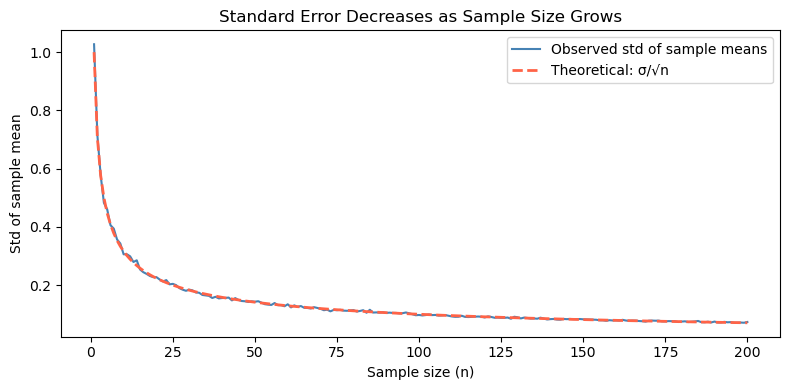

In [22]:
ns = np.arange(1, 201)
rng = np.random.default_rng(42)
observed_stds = [np.std([pop_exponential(rng, n).mean() for _ in range(1000)]) for n in ns]
theoretical_stds = [true_std / np.sqrt(n) for n in ns]

plt.figure(figsize=(8, 4))
plt.plot(ns, observed_stds, color='steelblue', lw=1.5, label='Observed std of sample means')
plt.plot(ns, theoretical_stds, color='tomato', lw=2, ls='--', label='Theoretical: σ/√n')
plt.xlabel('Sample size (n)')
plt.ylabel('Std of sample mean')
plt.title('Standard Error Decreases as Sample Size Grows')
plt.legend()
plt.tight_layout()
plt.savefig('clt_standard_error.png', dpi=150)
plt.show()


### Standard Error

The observed standard deviation of sample means (blue) virtually overlaps with the theoretical σ/√n curve (red dashed) across the entire range from n=1 to n=200. At n=1 the std is approximately 1.0 (equal to the population std); at n=100 it drops to about 0.1. This confirms that the CLT’s formula for the standard error is accurate in practice, and illustrates a key practical implication: to halve the uncertainty in your mean estimate, you need to quadruple your sample size.

样本均值的实际标准差（蓝色）在n=1到n=200的整个范围内与理论公式σ/√n（红色虚线）几乎完全重合。n=1时标准差约为1.0（等于总体标准差）；n=100时降至约0.1。这验证了CLT标准误公式在实践中的准确性，同时揭示了一个重要的实际含义：若要将均值估计的不确定性减半，样本量需要增加到四倍。

# summary

This project visualizes the Central Limit Theorem (CLT) — one of the most fundamental results in statistics — using simulation and four complementary visualizations.

The CLT states that the sampling distribution of the sample mean converges to a normal distribution as the sample size n increases, regardless of the shape of the underlying population distribution, provided the population has finite mean and variance. To demonstrate this, the project simulates repeated sampling from three structurally different populations: an exponential distribution (right-skewed), a uniform distribution (flat), and a bimodal distribution (two peaks).

The four visualizations build a complete picture of the theorem:

1.	The sampling distribution plot shows how the distribution of sample means transitions from the skewed shape of the exponential population at n=1 to a near-perfect bell curve by n=100, with the theoretical normal overlay confirming the fit at each step;
2.	The cross-distribution comparison demonstrates the universality of the CLT — all three populations, despite having completely different shapes, produce sampling distributions that converge to normal by n=30;
3.	The Q-Q plots provide a more rigorous diagnostic, revealing how tail behavior improves with n and confirming normality more sensitively than histograms alone;
4.	The standard error plot verifies the quantitative prediction of the CLT: the observed spread of sample means follows σ/√n almost exactly, illustrating the practical implication that halving estimation uncertainty requires quadrupling the sample size.

Together, the four visualizations move from intuitive demonstration to theoretical verification, making the CLT concrete, measurable, and universally applicable.


本项目通过模拟与四组可视化，直观展示统计学中最重要的基础定理之一——中心极限定理（CLT）。

CLT 指出：无论原始总体分布的形状如何，只要总体具有有限的均值和方差，样本均值的抽样分布随样本量 n 的增大趋向于正态分布。为证明这一点，本项目从三种结构完全不同的总体分布出发进行重复抽样：指数分布（右偏）、均匀分布（平坦）和双峰分布（两个峰）。

四组可视化共同构建了对定理的完整展示：

1.	抽样分布图展示了样本均值的分布如何从n=1时指数总体的偏态形状，逐步过渡到n=100时几乎完美的钟形曲线，每一步都有理论正态曲线叠加对照；
2.	跨分布对比图展示了CLT的普适性——三种形状截然不同的总体分布，到n=30时均产生接近正态的抽样分布；
3.	Q-Q图提供了更严格的诊断，清晰呈现尾部行为随n改善的过程，比直方图更敏感地确认正态性；
4.	标准误图验证了CLT的定量预测：样本均值的实际标准差与理论公式σ/√n几乎完全吻合，同时揭示了一个重要的实践含义——估计不确定性减半需要样本量增加到四倍。

